# Módulo 1 · Del registro de casos al panel distrito-semana con etiqueta de brote

**Tesis:** Modelo de machine learning para la predicción temprana de brotes de dengue a nivel distrital en el Perú.

## ¿Qué hace este módulo?

Toma la base cruda de vigilancia del MINSA, donde **cada fila es un caso notificado**, y la convierte en una tabla donde **cada fila es un distrito en una semana**, con:

1. el número de casos de esa semana,
2. la **etiqueta de brote** (lo que el modelo va a aprender a predecir),
3. las **variables predictoras** construidas solo con información del pasado,
4. el **objetivo futuro** a 2 y 4 semanas,
5. la **partición temporal** en entrenamiento, validación y prueba.

Todo lo demás de la tesis (clima, El Niño, vecinos, modelos, SHAP, tablero) se apoya en esta tabla. Si este módulo está mal, todo lo que viene después está mal, aunque las métricas se vean bonitas.

## ¿Dónde encaja?

```
MÓDULO 1 (este)         MÓDULO 2          MÓDULO 3           MÓDULO 4          MÓDULO 5
casos crudos      →   + clima y ICEN  →  + vecinos y     →  modelos y     →  tablero
panel + etiqueta                          censo              SHAP              Streamlit
```

## Sobre los datos de este notebook

Para que puedas correrlo **hoy**, el notebook genera datos **sintéticos** con el mismo formato que la base del MINSA (una fila por caso, con ubigeo, año, semana, enfermedad y tipo de diagnóstico). Cuando descargues la base real, cambias una sola línea (`USAR_DATOS_REALES = True`) y todo lo demás funciona igual. **Los números que ves aquí no son resultados de tu tesis**; solo sirven para entender el proceso.

## Paso 0 · Librerías

- **pandas / numpy:** manejo de tablas y cálculos.
- **epiweeks:** convierte año + semana epidemiológica en fecha real, siguiendo el calendario oficial (semanas de domingo a sábado). Lo explico en el paso 3.
- **matplotlib:** para el gráfico de verificación.

En Google Colab ejecuta primero `!pip install epiweeks`.

In [1]:
# !pip install epiweeks        # <- descomenta esta línea en Google Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from epiweeks import Week, Year

## Paso 1 · Configuración: todas las decisiones en un solo lugar

Todas las decisiones metodológicas están aquí arriba, con nombre. Así, si el jurado pregunta "¿y si el brote se define con 4 semanas en vez de 3?", cambias un número, vuelves a correr y respondes con datos. Eso se llama **análisis de sensibilidad**.

| Parámetro | Valor | Qué significa |
|---|---|---|
| `TIPOS_VALIDOS` | C y P | Solo casos confirmados (C) y probables (P). Según el diccionario de datos del MINSA, el campo `tipo_dx` también tiene casos sospechosos (S), que se excluyen porque todavía no cumplen la definición de caso. |
| `MIN_CASOS` | 5 | Un brote necesita al menos 5 casos... |
| `MIN_SEMANAS` | 3 | ...acumulados en al menos 3 semanas **seguidas** con casos. |
| `GAP_CIERRE` | 2 | El brote termina cuando hay 2 semanas seguidas sin casos. |
| `HORIZONTES` | 2 y 4 | Cuántas semanas antes queremos anticipar el brote. |
| `FIN_TRAIN`, `FIN_VAL` | 2021, 2022 | Entrenamos hasta 2021, validamos en 2022, probamos en 2023. |

Los tres números de la regla de brote (5, 3, 2) vienen de la definición que usaron Dostal et al. (2022) con datos del CDC Perú.

In [2]:
USAR_DATOS_REALES = False
RUTA_CSV = "vigilancia_dengue.csv"

COLUMNAS = {              # nombre en el CSV del MINSA  ->  nombre que usamos
    "ubigeo": "ubigeo",
    "ano": "anio",
    "semana": "semana",
    "enfermedad": "enfermedad",
    "tipo_dx": "tipo_dx",
}
TIPOS_VALIDOS = ["C", "P"]
MIN_CASOS, MIN_SEMANAS, GAP_CIERRE = 5, 3, 2
HORIZONTES = [2, 4]
FIN_TRAIN, FIN_VAL = "2021-12-31", "2022-12-31"

## Paso 2 · Obtener los datos

### Opción A: base real
Antes de cargar la base real, **mira sus primeras líneas** para saber el separador, la codificación y el nombre exacto de las columnas, y ajusta el diccionario `COLUMNAS`. Un detalle crucial: se lee el `ubigeo` **como texto** (`dtype=str`). Si pandas lo lee como número, el ubigeo `010101` se convierte en `10101` y pierdes el cero de Amazonas.

### Opción B: datos sintéticos
El generador crea 40 distritos entre 2010 y 2023. Cada distrito tiene un nivel base de casos, una estacionalidad (más casos en verano) y, algunos años al azar, una "ola" con forma de campana que simula un brote. Luego convierte los conteos en filas individuales, como en la base real, y mete un 10 % de casos sospechosos (S) para que la limpieza tenga algo que limpiar. Además, genera ubigeos como **números enteros** a propósito, para reproducir el problema del cero perdido.

In [3]:
def generar_datos_sinteticos(n_distritos=40, anios=range(2010, 2024), semilla=7):
    rng = np.random.default_rng(semilla)
    semanas = [(w.year, w.week) for a in anios for w in Year(a).iterweeks()]
    t = np.arange(len(semanas))
    estac = 1 + 0.6 * np.sin(2 * np.pi * (np.array([w for _, w in semanas]) - 1) / 52)
    filas = []
    for d in range(n_distritos):
        ubigeo = int(f"{rng.integers(1, 26):02d}{rng.integers(1, 10):02d}{d + 1:02d}")
        curva = np.full(len(semanas), rng.choice([0.02, 0.08, 0.25]))
        for a in anios:
            if rng.random() < 0.30:
                inicio = [i for i, (yy, _) in enumerate(semanas) if yy == a][0]
                pico = inicio + rng.integers(4, 20)
                ancho, alto = rng.integers(3, 7), rng.uniform(3, 60)
                curva += alto * np.exp(-0.5 * ((t - pico) / ancho) ** 2)
        for (a, w), c in zip(semanas, rng.poisson(curva * estac)):
            for _ in range(c):
                filas.append((ubigeo, a, w, "DENGUE SIN SEÑALES DE ALARMA",
                              rng.choice(["C", "P", "S"], p=[0.45, 0.45, 0.10])))
    return pd.DataFrame(filas, columns=["ubigeo", "ano", "semana", "enfermedad", "tipo_dx"])

if USAR_DATOS_REALES:
    with open(RUTA_CSV, encoding="latin-1") as f:
        for _ in range(3):
            print(f.readline().strip())
    crudo = pd.read_csv(RUTA_CSV, sep=None, engine="python",
                        dtype={"ubigeo": str}, encoding="latin-1")
else:
    crudo = generar_datos_sinteticos()

print(f"Filas (casos notificados): {len(crudo):,}")
crudo.head()

Filas (casos notificados): 92,317


,ubigeo,ano,semana,enfermedad,tipo_dx
0,240601,2010,2,DENGUE SIN SEÑALES DE ALARMA,C
1,240601,2010,12,DENGUE SIN SEÑALES DE ALARMA,S
2,240601,2010,14,DENGUE SIN SEÑALES DE ALARMA,P
3,240601,2010,15,DENGUE SIN SEÑALES DE ALARMA,P
4,240601,2010,16,DENGUE SIN SEÑALES DE ALARMA,S


## Paso 3 · Limpieza

Cuatro decisiones, cada una con su razón:

1. **Ubigeo a 6 dígitos con ceros a la izquierda** (`zfill(6)`). El ubigeo es la **llave** que une esta tabla con el clima, el censo y el mapa. Si en una tabla dice `10101` y en otra `010101`, el cruce falla en silencio y pierdes distritos sin darte cuenta. El `split(".")` elimina un posible `.0` que aparece cuando el número se guardó como decimal.
2. **Solo filas de dengue.** Uso `contains("DENGUE")` para aceptar las tres formas clínicas (sin signos de alarma, con signos de alarma y grave).
3. **Solo confirmados y probables.** Es la misma decisión de Dostal et al. (2022) y Mills y Donnelly (2024): sumar ambos porque en epidemia no se confirma cada caso por laboratorio. Los sospechosos (S) se excluyen.
4. **Semanas entre 1 y 53.** Cualquier otro valor es un error de digitación.

In [4]:
def limpiar(crudo):
    df = crudo.rename(columns=COLUMNAS)[list(COLUMNAS.values())].copy()
    df["ubigeo"] = df["ubigeo"].astype(str).str.split(".").str[0].str.zfill(6)
    df = df[df["enfermedad"].str.upper().str.contains("DENGUE", na=False)]
    df = df[df["tipo_dx"].isin(TIPOS_VALIDOS)]
    df = df[df["semana"].between(1, 53)]
    return df

df = limpiar(crudo)
print(f"Antes: {len(crudo):,} filas  ->  después: {len(df):,} filas  "
      f"({len(crudo) - len(df):,} sospechosos u otros eliminados)")
corto = crudo[crudo["ubigeo"].astype(str).str.len() < 6]["ubigeo"].iloc[0]
print(f"Ubigeo que llegó sin su cero: {corto}  ->  corregido: {str(corto).zfill(6)}")

Antes: 92,317 filas  ->  después: 83,120 filas  (9,197 sospechosos u otros eliminados)
Ubigeo que llegó sin su cero: 10902  ->  corregido: 010902


## Paso 4 · De "año + semana" a una fecha real

¿Por qué no basta con el número de semana? Por tres razones:

- **Hay años con 53 semanas epidemiológicas.** Si ordenas por (año, semana) y calculas "la semana anterior" restando 1, en la semana 1 de 2021 obtienes "semana 0", que no existe. Con fechas reales, la semana anterior es siempre *fecha − 7 días*, sin excepciones.
- **La semana 1 no empieza el 1 de enero.** Las semanas epidemiológicas van de domingo a sábado, y la semana 1 es la primera que tiene al menos 4 días en el año nuevo. Por eso la semana 1 de un año puede empezar a fines de diciembre del año anterior.
- **Para cruzar con el clima** (paso siguiente de la tesis), el clima viene por día. Con la fecha de inicio de cada semana puedes sumar la lluvia de esos 7 días exactos.

La librería `epiweeks` implementa este calendario oficial.

In [5]:
def semana_a_fecha(anio, semana):
    try:
        return pd.Timestamp(Week(int(anio), int(semana)).startdate())
    except ValueError:              # semana 53 en un año que no la tiene
        return pd.NaT

anios_53 = [a for a in range(2010, 2027) if len(list(Year(a).iterweeks())) == 53]
print("Años con 53 semanas epidemiológicas:", anios_53)
print("Semana 1 de 2023 empieza el:", Week(2023, 1).startdate())
print("Semana 1 de 2021 empieza el:", Week(2021, 1).startdate())

Años con 53 semanas epidemiológicas: [2014, 2020, 2025]
Semana 1 de 2023 empieza el: 2023-01-01
Semana 1 de 2021 empieza el: 2021-01-03


## Paso 5 · Agregar por distrito-semana y completar los ceros invisibles

Primero se **cuentan** los casos por (ubigeo, año, semana): de miles de filas de personas pasamos a una fila por distrito-semana.

Pero aparece el problema más traicionero del proyecto: **las semanas sin casos no existen en la base**. Si en un distrito no hubo casos en marzo, no hay ninguna fila que diga "marzo: 0". Simplemente no está. Si no lo corriges:

- `shift(1)` ("la semana anterior") te devuelve en realidad *la última semana que tuvo casos*, que puede ser de hace cinco meses.
- La regla de brote cree que las semanas son consecutivas cuando no lo son.
- El modelo nunca ve ejemplos de "semana tranquila", que son la mayoría.

**Solución: construir una grilla completa.** Se crea el producto cartesiano de *todos los distritos* × *todas las semanas* del período y se rellena con 0 donde no hubo registro (`reindex(..., fill_value=0)`). Es la misma decisión de Dostal et al. (2022): un distrito-semana sin notificaciones cuenta como 0 casos.

In [6]:
def construir_panel(df):
    conteo = df.groupby(["ubigeo", "anio", "semana"]).size().rename("casos").reset_index()

    pares = conteo[["anio", "semana"]].drop_duplicates()
    pares["fecha"] = [semana_a_fecha(a, s) for a, s in zip(pares.anio, pares.semana)]
    conteo = conteo.merge(pares, on=["anio", "semana"]).dropna(subset=["fecha"])

    semanas = pd.date_range(conteo.fecha.min(), conteo.fecha.max(), freq="7D")
    grilla = pd.MultiIndex.from_product([conteo.ubigeo.unique(), semanas],
                                        names=["ubigeo", "fecha"])
    panel = (conteo.set_index(["ubigeo", "fecha"])["casos"]
                   .reindex(grilla, fill_value=0).reset_index())
    panel["anio_epi"] = [Week.fromdate(f).year for f in panel.fecha]
    panel["semana_epi"] = [Week.fromdate(f).week for f in panel.fecha]
    return panel.sort_values(["ubigeo", "fecha"]).reset_index(drop=True)

panel = construir_panel(df)
n_dist, n_sem = panel.ubigeo.nunique(), panel.fecha.nunique()
print(f"{n_dist} distritos × {n_sem} semanas = {n_dist * n_sem:,} filas  (panel: {len(panel):,})")
print(f"Semanas con 0 casos: {(panel.casos == 0).mean():.0%} del panel")
panel.head()

40 distritos × 730 semanas = 29,200 filas  (panel: 29,200)
Semanas con 0 casos: 78% del panel


,ubigeo,fecha,casos,anio_epi,semana_epi
0,010902,2010-01-03,0,2010,1
1,010902,2010-01-10,0,2010,2
2,010902,2010-01-17,0,2010,3
3,010902,2010-01-24,0,2010,4
4,010902,2010-01-31,0,2010,5


## Paso 6 · La etiqueta de brote (lo que el modelo aprende a predecir)

### La regla en palabras
Un distrito está en brote durante un **episodio** de casos que contiene un **disparador**:

- **Disparador:** 3 o más semanas **seguidas con casos** que en total sumen 5 o más.
- **Episodio:** un tramo que empieza en la primera semana con casos y termina en la última semana con casos antes de que aparezcan **2 semanas seguidas en cero**. Una sola semana en cero en medio no corta el episodio.
- Si el episodio contiene un disparador, **todas** sus semanas se marcan como brote (1). Si no, todas quedan en 0.

### Ejemplo a mano
Casos semanales: `0 1 0 2 3 1 4 0 1 0 0 0 2 0 ...`

- Semana 1: aparece 1 caso → empieza un episodio.
- Semana 2: un 0 → no corta, porque es uno solo.
- Semanas 3 a 6: `2, 3, 1, 4` → 4 semanas seguidas con casos que suman 10 ⇒ **hay disparador**.
- Semana 7: un 0, no corta. Semana 8: 1 caso, sigue.
- Semanas 9 y 10: dos ceros seguidos ⇒ **el episodio termina en la semana 8**.
- Resultado: las semanas 1 a 8 son brote, **incluida la semana 1**, aunque en ese momento solo había 1 caso.

Ese último punto es clave: **la etiqueta se decide mirando hacia adelante**. En la semana 1 nadie sabía que venía un brote; lo sabemos porque vimos lo que pasó después. Por eso esta columna **solo se usa como objetivo, nunca como variable de entrada**. Es la "trampa 1" del dossier.

### El código
Dos funciones: `tiene_disparador` recorre un tramo buscando la racha, y `etiquetar_brotes` recorre la serie armando episodios.

In [7]:
def tiene_disparador(seg, min_casos=MIN_CASOS, min_semanas=MIN_SEMANAS):
    largo, suma = 0, 0
    for v in seg:
        if v > 0:
            largo, suma = largo + 1, suma + v
            if largo >= min_semanas and suma >= min_casos:
                return True
        else:                       # un cero rompe la racha
            largo, suma = 0, 0
    return False

def etiquetar_brotes(casos, gap_cierre=GAP_CIERRE):
    c = np.asarray(casos)
    y = np.zeros(len(c), dtype=int)
    i = 0
    while i < len(c):
        if c[i] == 0:
            i += 1
            continue
        inicio = fin = i            # empieza un episodio
        ceros, j = 0, i + 1
        while j < len(c):
            if c[j] > 0:
                fin, ceros = j, 0
            else:
                ceros += 1
                if ceros >= gap_cierre:
                    break           # 2 ceros seguidos: el episodio terminó
            j += 1
        if tiene_disparador(c[inicio:fin + 1]):
            y[inicio:fin + 1] = 1
        i = fin + 1
    return y

ejemplo = [0, 1, 0, 2, 3, 1, 4, 0, 1, 0, 0, 0, 2, 0, 0, 1, 1, 1, 0, 0]
print("casos   :", ejemplo)
print("etiqueta:", etiquetar_brotes(ejemplo).tolist())

casos   : [0, 1, 0, 2, 3, 1, 4, 0, 1, 0, 0, 0, 2, 0, 0, 1, 1, 1, 0, 0]
etiqueta: [0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


Fíjate en el final del ejemplo: `1, 1, 1` son tres semanas seguidas con casos, pero suman 3, no 5. **No es brote.** Y el `2` aislado tampoco. La regla distingue casos esporádicos de transmisión sostenida.

## Paso 7 · El estado de brote "en tiempo real"

Como la etiqueta mira al futuro, necesitamos otra versión de la misma regla que **solo mire el pasado**, para dos cosas: dársela al modelo como variable ("¿el distrito ya está en brote hoy?") y construir la línea base de persistencia.

Funciona como un **interruptor** que avanza semana a semana:

- Lleva la cuenta de la racha actual (semanas seguidas con casos y su suma) y de los ceros seguidos.
- Se **enciende** en el momento en que la racha cumple la regla (3 semanas, 5 casos).
- Se **apaga** cuando ve 2 ceros seguidos.
- En cada semana solo usa lo que ya ocurrió.

Compara con la etiqueta en el mismo ejemplo: la etiqueta marca brote desde la semana 1, pero el interruptor recién se enciende en la semana 5, cuando se completa la racha `2, 3, 1`. **Esa diferencia de 4 semanas es el retraso de detección**: el tiempo que pasa entre que empieza un brote y que la vigilancia puede confirmarlo con la regla. Tu modelo existe para ganar esas semanas.

In [8]:
def brote_en_tiempo_real(casos, min_casos=MIN_CASOS, min_semanas=MIN_SEMANAS,
                         gap_cierre=GAP_CIERRE):
    estado = np.zeros(len(casos), dtype=int)
    activo, largo, suma, ceros = False, 0, 0, 0
    for t, v in enumerate(casos):
        if v > 0:
            largo, suma, ceros = largo + 1, suma + v, 0
        else:
            largo, suma, ceros = 0, 0, ceros + 1
        if not activo and largo >= min_semanas and suma >= min_casos:
            activo = True           # se enciende
        if activo and ceros >= gap_cierre:
            activo = False          # se apaga
        estado[t] = int(activo)
    return estado

def semanas_desde_ultimo(estado):
    out, ultimo = np.full(len(estado), 999, dtype=int), None
    for t, e in enumerate(estado):
        if e == 1:
            ultimo = t
        if ultimo is not None:
            out[t] = t - ultimo
    return out

pd.DataFrame({"semana": range(len(ejemplo)), "casos": ejemplo,
              "etiqueta (mira el futuro)": etiquetar_brotes(ejemplo),
              "tiempo real (solo pasado)": brote_en_tiempo_real(ejemplo)}).set_index("semana").T

semana,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
casos,0,1,0,2,3,1,4,0,1,0,0,0,2,0,0,1,1,1,0,0
etiqueta (mira el futuro),0,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0
tiempo real (solo pasado),0,0,0,0,0,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0


## Paso 8 · Variables predictoras

Regla de oro: **cada variable de la fila de la semana *t* se calcula solo con semanas ≤ *t***. Todas se calculan **dentro de cada distrito** (`groupby("ubigeo")`) para que el rezago de un distrito nunca tome datos del distrito anterior en la tabla.

| Variable | Qué es | Por qué ayuda |
|---|---|---|
| `casos_lag0` … `casos_lag7` | Casos de la semana *t*, *t−1*, …, *t−7* | La historia reciente es el predictor más fuerte. `shift(k)` mueve la columna *k* filas hacia abajo. |
| `casos_4s`, `casos_12s` | Suma de las últimas 4 y 12 semanas | Resumen de corto y mediano plazo, menos ruidoso que semanas sueltas. |
| `tendencia_4s` | Pendiente de la recta que mejor ajusta las últimas 4 semanas | Distingue "10 casos y subiendo" de "10 casos y bajando". |
| `brote_rt` | Estado del interruptor del paso 7 | ¿El distrito ya está en brote hoy? |
| `sem_desde_brote` | Semanas desde que el interruptor estuvo encendido por última vez (999 si nunca) | Un brote reciente deja población inmune a ese serotipo. |
| `sem_sin`, `sem_cos` | Semana del año como punto en un círculo | Estacionalidad. |

### La fórmula de la tendencia
Para 4 puntos equiespaciados, la pendiente de mínimos cuadrados se reduce a una suma ponderada:

$$\text{tendencia} = \frac{3\,c_t + c_{t-1} - c_{t-2} - 3\,c_{t-3}}{10}$$

Pesa más los extremos: si la semana actual es mucho mayor que la de hace 3 semanas, la pendiente es positiva. Así no hace falta ajustar una regresión por cada fila.

### ¿Por qué seno y coseno?
Si le das al modelo la semana como número, cree que la semana 52 y la semana 1 están lejísimos (52 − 1 = 51), cuando en realidad son vecinas. Al convertir la semana en un ángulo y tomar seno y coseno, cada semana es un punto en un círculo y la 52 queda pegada a la 1.

In [9]:
def construir_variables(panel):
    p = panel.sort_values(["ubigeo", "fecha"]).copy()
    g = p.groupby("ubigeo")["casos"]

    for k in range(8):
        p[f"casos_lag{k}"] = g.shift(k)
    p["casos_4s"] = g.transform(lambda s: s.rolling(4).sum())
    p["casos_12s"] = g.transform(lambda s: s.rolling(12).sum())
    p["tendencia_4s"] = (3 * p.casos_lag0 + p.casos_lag1 - p.casos_lag2 - 3 * p.casos_lag3) / 10

    p["brote_rt"] = g.transform(lambda s: pd.Series(brote_en_tiempo_real(s.values), index=s.index))
    p["sem_desde_brote"] = p.groupby("ubigeo")["brote_rt"].transform(
        lambda s: pd.Series(semanas_desde_ultimo(s.values), index=s.index))

    angulo = 2 * np.pi * p["semana_epi"] / 52.18
    p["sem_sin"], p["sem_cos"] = np.sin(angulo), np.cos(angulo)
    return p

variables = construir_variables(panel)

# mostramos el arranque de un brote en el distrito con más casos
top = variables.groupby("ubigeo")["casos"].sum().idxmax()
v = variables[variables.ubigeo == top].reset_index(drop=True)
i0 = int(v.index[(v.brote_rt == 1) & (v.brote_rt.shift(1) == 0) & (v.index > 20)][0])
v.loc[i0 - 6:i0 + 3, ["fecha", "casos", "casos_lag1", "casos_lag2", "casos_4s", "tendencia_4s", "brote_rt"]]

,fecha,casos,casos_lag1,casos_lag2,casos_4s,tendencia_4s,brote_rt
103,2011-12-25,0,0.0,0.0,0.0,0.0,0
104,2012-01-01,0,0.0,0.0,0.0,0.0,0
105,2012-01-08,0,0.0,0.0,0.0,0.0,0
106,2012-01-15,0,0.0,0.0,0.0,0.0,0
107,2012-01-22,1,0.0,0.0,1.0,0.3,0
108,2012-01-29,1,1.0,0.0,2.0,0.4,0
109,2012-02-05,6,1.0,1.0,8.0,1.8,1
110,2012-02-12,13,6.0,1.0,21.0,4.1,1
111,2012-02-19,20,13.0,6.0,40.0,6.4,1
112,2012-02-26,29,20.0,13.0,68.0,7.6,1


## Paso 9 · El objetivo futuro

Ahora se calcula la etiqueta de brote (paso 6) y se **sube** *h* semanas con `shift(-h)`. Así, en la fila de la semana *t* queda escrita la respuesta de la semana *t + h*:

| fecha | casos (dato de hoy) | brote (etiqueta de hoy) | y_h2 (lo que hay que predecir) |
|---|---|---|---|
| semana 10 | 1 | 0 | brote de la semana 12 |
| semana 11 | 3 | 1 | brote de la semana 13 |

Cada fila responde la pregunta: *"Con lo que sé hoy, ¿este distrito estará en brote dentro de h semanas?"*

También se marca `sin_brote_hoy`: las filas donde el interruptor está apagado. Ahí está el valor real de la alerta temprana, como se verá en el paso 12.

In [10]:
def agregar_objetivos(p):
    p = p.copy()
    p["brote"] = p.groupby("ubigeo")["casos"].transform(
        lambda s: pd.Series(etiquetar_brotes(s.values), index=s.index))
    for h in HORIZONTES:
        p[f"y_h{h}"] = p.groupby("ubigeo")["brote"].shift(-h)
    p["sin_brote_hoy"] = (p["brote_rt"] == 0).astype(int)
    return p

datos = agregar_objetivos(variables)
print(f"Semanas de brote: {datos.brote.mean():.1%} del panel")
d0 = datos[datos.ubigeo == top].reset_index(drop=True)
j0 = int(d0.index[(d0.brote == 1) & (d0.brote.shift(1) == 0) & (d0.index > 20)][0])
d0.loc[j0 - 5:j0 + 5, ["fecha", "casos", "brote", "brote_rt", "y_h2", "y_h4"]]

Semanas de brote: 15.4% del panel


,fecha,casos,brote,brote_rt,y_h2,y_h4
102,2011-12-18,0,0,0,0.0,0.0
103,2011-12-25,0,0,0,0.0,1.0
104,2012-01-01,0,0,0,0.0,1.0
105,2012-01-08,0,0,0,1.0,1.0
106,2012-01-15,0,0,0,1.0,1.0
107,2012-01-22,1,1,0,1.0,1.0
108,2012-01-29,1,1,0,1.0,1.0
109,2012-02-05,6,1,1,1.0,1.0
110,2012-02-12,13,1,1,1.0,1.0
111,2012-02-19,20,1,1,1.0,1.0


### Cómo leer esta tabla (es la más importante del notebook)

Con los datos sintéticos, mira la fila del **25 de diciembre de 2011**: el distrito tiene **0 casos**, no está en brote ni según la etiqueta ni según el interruptor... y sin embargo `y_h4` ya vale **1**. Esa fila le dice al modelo: *"aunque hoy no se ve nada, dentro de 4 semanas este distrito estará en brote"*.

Sigue bajando: la etiqueta de brote empieza el 22 de enero, pero el interruptor en tiempo real recién se enciende el 5 de febrero. Es decir:

- **4 semanas antes** del inicio real, `y_h4` ya pide la alerta,
- **2 semanas después** del inicio real, la regla recién confirma el brote.

Esa ventana de unas 6 semanas es exactamente el espacio donde tu modelo puede aportar. Para acertar en filas así, el modelo necesitará señales que no son los casos del propio distrito: la **lluvia y temperatura** de semanas previas, el **ICEN** y los **casos en distritos vecinos**. Por eso existen los módulos 2 y 3.

## Paso 10 · Verificación visual

Antes de confiar en cualquier número, **mira un distrito**. En el gráfico:

- las barras son los casos semanales,
- la franja roja es la etiqueta de brote (lo que se decide con el diario del lunes),
- la línea negra escalonada es el interruptor en tiempo real.

Deberías ver que la franja roja **empieza antes** que la línea negra en cada brote: esa distancia es el retraso de detección. Y al final pasa lo contrario: la línea negra se apaga un poco **después**, porque necesita ver las 2 semanas en cero para estar segura de que terminó. Haz esta revisión con 5 o 6 distritos reales que conozcas (Piura, Sullana, Tarapoto) y contrasta con las fechas de las alertas del CDC.

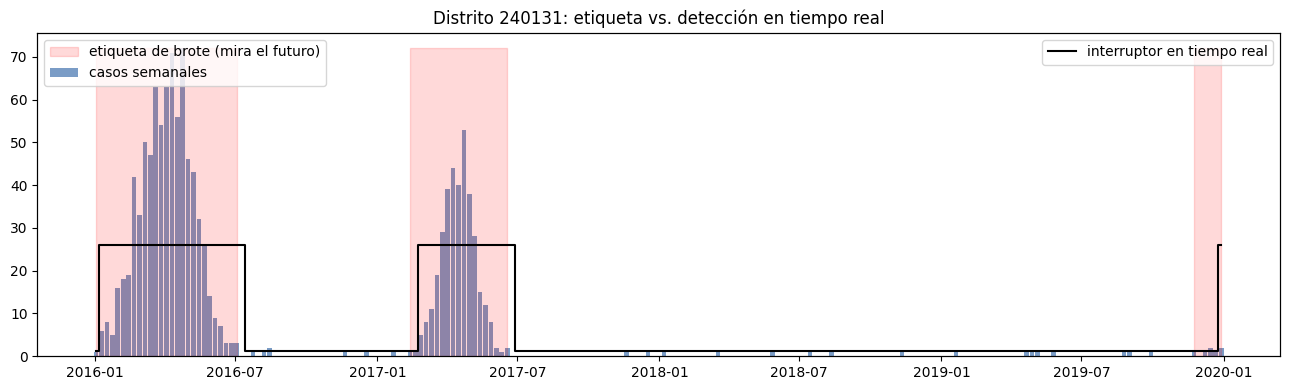

In [11]:
distrito = datos.groupby("ubigeo")["brote"].sum().idxmax()
d = datos[(datos.ubigeo == distrito) & (datos.fecha.between("2016-01-01", "2019-12-31"))]

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(d.fecha, d.casos, width=6, color="#7a9cc6", label="casos semanales")
ax.fill_between(d.fecha, 0, d.casos.max(), where=d.brote == 1, color="red", alpha=0.15,
                step="mid", label="etiqueta de brote (mira el futuro)")
ax2 = ax.twinx()
ax2.step(d.fecha, d.brote_rt, where="mid", color="black", lw=1.5, label="interruptor en tiempo real")
ax2.set_ylim(-0.05, 3); ax2.set_yticks([])
ax.set_title(f"Distrito {distrito}: etiqueta vs. detección en tiempo real")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()

## Paso 11 · Prueba anti-fuga: "si cambio el futuro, ¿cambia el pasado?"

Esta es la prueba que te va a salvar en la sustentación. La idea es simple:

1. Elige una fecha de corte.
2. **Inventa** datos después de esa fecha (aquí, 30 casos por semana en todos los distritos).
3. Vuelve a calcular las variables.
4. Si **alguna** variable de antes del corte cambió, esa variable estaba mirando el futuro. Hay fuga.

El resultado esperado es doble y ambas cosas son correctas:

- Las **variables** antes del corte **no cambian** ⇒ no hay fuga.
- La **etiqueta** antes del corte **sí cambia** en algunas semanas ⇒ confirma que la etiqueta mira el futuro y que hicimos bien en usarla solo como objetivo.

Cuando agregues clima y vecinos en los siguientes módulos, vuelves a correr esta misma prueba.

In [12]:
corte = pd.Timestamp("2018-06-03")
panel_alterado = panel.copy()
despues = panel_alterado.fecha > corte
panel_alterado.loc[despues, "casos"] = 30

orig = construir_variables(panel)
alt = construir_variables(panel_alterado)
cols = [c for c in orig.columns if c.startswith(("casos_", "tendencia", "brote_rt", "sem_"))]
iguales = orig.loc[orig.fecha <= corte, cols].equals(alt.loc[alt.fecha <= corte, cols])
print("¿Las variables del pasado quedaron iguales?", iguales)

et_orig = agregar_objetivos(orig).loc[lambda x: x.fecha <= corte, "brote"].values
et_alt = agregar_objetivos(alt).loc[lambda x: x.fecha <= corte, "brote"].values
print("Semanas pasadas cuya ETIQUETA cambió:", int((et_orig != et_alt).sum()))

¿Las variables del pasado quedaron iguales? True
Semanas pasadas cuya ETIQUETA cambió: 26


## Paso 12 · Partición temporal (con frontera)

En series de tiempo **no se mezcla al azar**. Si entrenas con marzo de 2023 y pruebas con febrero de 2023, el modelo ya "vio" la epidemia. La partición respeta el calendario:

```
  2010 ─────────────── 2021 │ 2022 │ 2023
        ENTRENAMIENTO       │ VAL  │ PRUEBA
                         ▲
                 frontera de h semanas
```

**La frontera:** una fila de la última semana de 2021 con h = 2 tiene como objetivo una semana de enero de 2022, que pertenece a validación. Si la dejas en entrenamiento, el modelo aprende con una respuesta del período de validación. Por eso se exige que **la fecha del objetivo** (fecha + h semanas) caiga dentro del mismo período. Se pierden unas pocas filas, pero la evaluación queda limpia.

También se eliminan las primeras 12 semanas de cada distrito, donde los rezagos todavía no existen (valores vacíos).

In [13]:
def particionar(p, h):
    objetivo = f"y_h{h}"
    d = p.dropna(subset=[objetivo, "casos_lag7", "casos_12s"])
    fecha_obj = d["fecha"] + pd.Timedelta(weeks=h)
    train = d[fecha_obj <= FIN_TRAIN]
    val = d[(d.fecha > FIN_TRAIN) & (fecha_obj <= FIN_VAL)]
    test = d[d.fecha > FIN_VAL]
    return train, val, test

for h in HORIZONTES:
    tr, va, te = particionar(datos, h)
    print(f"h={h}: train {len(tr):>6,} filas hasta {tr.fecha.max().date()} | "
          f"val {len(va):>5,} desde {va.fecha.min().date()} | test {len(te):>5,} desde {te.fecha.min().date()}")

h=2: train 24,520 filas hasta 2021-12-12 | val 2,000 desde 2022-01-02 | test 2,000 desde 2023-01-01
h=4: train 24,440 filas hasta 2021-11-28 | val 1,920 desde 2022-01-02 | test 1,920 desde 2023-01-01


## Paso 13 · Primera evidencia: la línea base de persistencia y el retraso de detección

Todavía no hay modelo, pero ya puedes producir dos resultados que justifican la tesis.

**La persistencia** predice: *"dentro de h semanas el distrito estará igual que hoy"*. Se evalúa en dos grupos:

- **Todas las filas:** la persistencia parece buenísima, porque la mayoría de semanas de brote son continuación de un brote que ya estaba encendido.
- **Solo distritos sin brote hoy:** la persistencia predice siempre "no habrá brote", así que su exhaustividad es **cero**. No detecta ni un solo brote nuevo.

Esto demuestra con números la "trampa 2": si reportas solo la métrica global, cualquier modelo parece excelente. El valor de tu tesis se mide en el segundo grupo.

**El retraso de detección** mide, para cada brote, cuántas semanas pasan desde su inicio real (etiqueta) hasta que el interruptor en tiempo real se enciende. Es tu argumento de motivación: *"con la regla, el brote se confirma X semanas tarde; el modelo busca anticiparlo"*.

In [14]:
from sklearn.metrics import precision_score, recall_score

tr, va, te = particionar(datos, 2)
nuevo = te[te.sin_brote_hoy == 1]
print("Persistencia, h = 2, conjunto de prueba")
print(f"  Todas las filas     -> precisión {precision_score(te.y_h2, te.brote_rt):.2f} | "
      f"exhaustividad {recall_score(te.y_h2, te.brote_rt):.2f}")
print(f"  Sin brote hoy       -> exhaustividad {recall_score(nuevo.y_h2, nuevo.brote_rt, zero_division=0):.2f} "
      f"(había {int(nuevo.y_h2.sum())} brotes nuevos por detectar)")

retrasos = []
for _, g in datos.groupby("ubigeo"):
    b, r = g.brote.values, g.brote_rt.values
    for i in np.where(np.diff(np.r_[0, b]) == 1)[0]:
        fin = i
        while fin < len(b) and b[fin] == 1:
            fin += 1
        detectado = np.where(r[i:fin] == 1)[0]
        if len(detectado):
            retrasos.append(detectado[0])
print(f"\nRetraso de detección: mediana {np.median(retrasos):.0f} semanas, "
      f"media {np.mean(retrasos):.1f} (en {len(retrasos)} brotes)")

Persistencia, h = 2, conjunto de prueba
  Todas las filas     -> precisión 0.88 | exhaustividad 0.89
  Sin brote hoy       -> exhaustividad 0.00 (había 33 brotes nuevos por detectar)

Retraso de detección: mediana 3 semanas, media 3.2 (en 188 brotes)


## Paso 14 · Guardar

Se guarda en **Parquet**, no en CSV: conserva los tipos (el ubigeo sigue siendo texto, la fecha sigue siendo fecha), pesa mucho menos y se lee más rápido. El módulo 2 empieza leyendo este archivo.

In [15]:
datos.to_parquet("panel_modulo1.parquet", index=False)
print("Guardado:", datos.shape)

Guardado: (29200, 24)


---
# Cómo explicarlo sin leer (guion de 2 minutos)

> "La base del MINSA trae una fila por cada caso. Lo primero que hago es limpiarla: dejo solo dengue confirmado y probable, y normalizo el ubigeo a seis dígitos porque es la llave para cruzar con clima y censo.
>
> Luego convierto año y semana epidemiológica en una fecha real, porque hay años con 53 semanas y porque el clima viene por día.
>
> Después cuento los casos por distrito y semana, y completo con ceros las semanas que no aparecen, porque en la base una semana sin casos simplemente no existe, y sin esos ceros los rezagos salen mal.
>
> Para la etiqueta uso la definición de brote de la literatura peruana: un episodio de casos que contiene al menos 3 semanas seguidas con casos que sumen 5 o más, y que termina con 2 semanas seguidas en cero. Esa etiqueta mira hacia el futuro, así que solo la uso como objetivo. Para el estado actual del distrito uso la misma regla pero en tiempo real, mirando solo el pasado.
>
> Las variables son rezagos de casos, sumas móviles, la tendencia de las últimas 4 semanas, el estado de brote en tiempo real y la estacionalidad codificada en seno y coseno. El objetivo es la etiqueta desplazada 2 o 4 semanas al futuro.
>
> Verifico que no haya fuga cambiando datos del futuro y comprobando que las variables del pasado no cambian. Y parto en el tiempo: entreno hasta 2021, valido en 2022 y pruebo en 2023, dejando una frontera para que ninguna respuesta cruce de un período a otro.
>
> Con esto ya muestro dos cosas: que la regla en tiempo real detecta los brotes con varias semanas de retraso, y que la persistencia no detecta ningún brote nuevo. Ese es el hueco que llena mi modelo."

# Preguntas que te pueden hacer sobre este módulo

- **¿Por qué rellenas con cero? ¿No podría ser un dato faltante?** Puede haber subregistro, pero en la vigilancia la ausencia de notificación se interpreta como cero casos notificados, igual que en Dostal et al. (2022). Lo discuto como limitación.
- **¿Qué pasa con los distritos creados durante el período?** Se fusionan con su distrito de origen para mantener series continuas. Es un paso que agrego al cargar la cartografía.
- **¿La semana es de inicio de síntomas o de notificación?** Según el diccionario de datos del MINSA, el campo `semana` corresponde a la **semana de inicio de síntomas** y el distrito es el **lugar probable de infección**. Aun así, en tiempo real los casos de las últimas semanas llegan incompletos por el retraso de notificación, y lo evalúo desplazando los rezagos una semana.
- **¿Por qué 5 casos y 3 semanas?** Es la definición publicada; además todo está parametrizado y reporto un análisis de sensibilidad con otros valores.

# Qué sigue

- **Módulo 2:** clima por distrito y semana (CHIRPS, ERA5-Land) con Google Earth Engine, más ICEN y ONI con rezago.
- **Módulo 3:** casos de distritos vecinos, variables del censo y filtro por altitud.
- **Módulo 4:** entrenamiento de modelos, estudio de ablación y SHAP.
- **Módulo 5:** tablero en Streamlit.